In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [52]:
np.random.seed(42)
n_samples = 500

In [53]:
income = np.random.randint(20000, 120000, n_samples)
age = np.random.randint(18, 70, n_samples)
credit_count = np.random.randint(0, 5, n_samples)

In [54]:
# Целевая переменная: 1 — не вернул кредит, 0 — вернул
# Чем ниже доход и выше количество кредитов, тем выше риск
default_prob = (120000 - income) * 0.00001 + credit_count * 0.1 + (70 - age) * 0.001
default = np.random.binomial(1, default_prob.clip(0, 1))

In [55]:
# Создание DataFrame
data = pd.DataFrame({
'Income': income,
'Age': age,
'Credit_Count': credit_count,
'Default': default
})

In [56]:
# Разделение на признаки и целевую переменную
X = data[['Income', 'Age', 'Credit_Count']]
y = data['Default']

In [57]:
# Делим данные на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)


In [58]:
# Создание и обучение модели XGBoost
model = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
model.fit(X_train, y_train)

C:\Users\administrator\tensorflow\pythonProject1\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [17:40:25] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [59]:
# Предсказания
y_pred = model.predict(X_test)

In [60]:
# Оценка точности
accuracy = accuracy_score(y_test, y_pred)
print(f"Точность модели: {accuracy * 100:.2f}%")

Точность модели: 74.67%


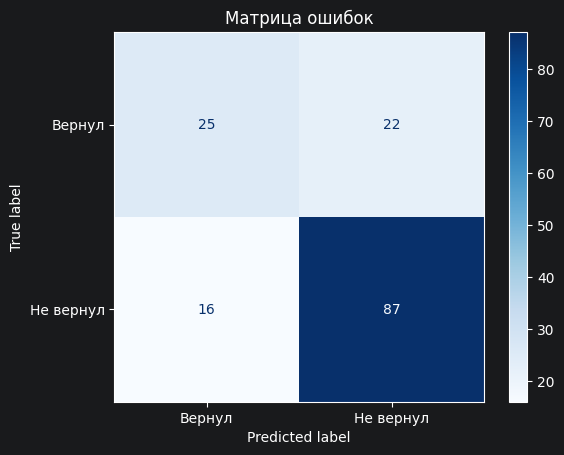

In [61]:
# Визуализация матрицы ошибок
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Вернул", "Не вернул"])
disp.plot(cmap='Blues')
plt.title("Матрица ошибок")
plt.show()

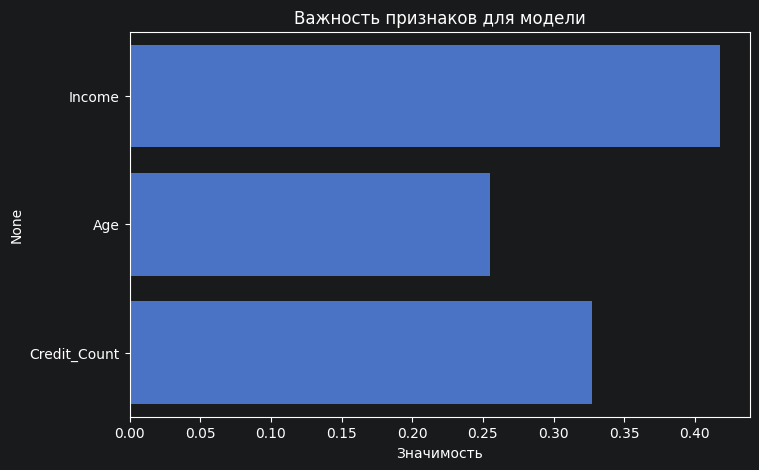

In [62]:
# Важность признаков
plt.figure(figsize=(8,5))
sns.barplot(x=model.feature_importances_, y=X.columns)
plt.title('Важность признаков для модели')
plt.xlabel('Значимость')
plt.show()

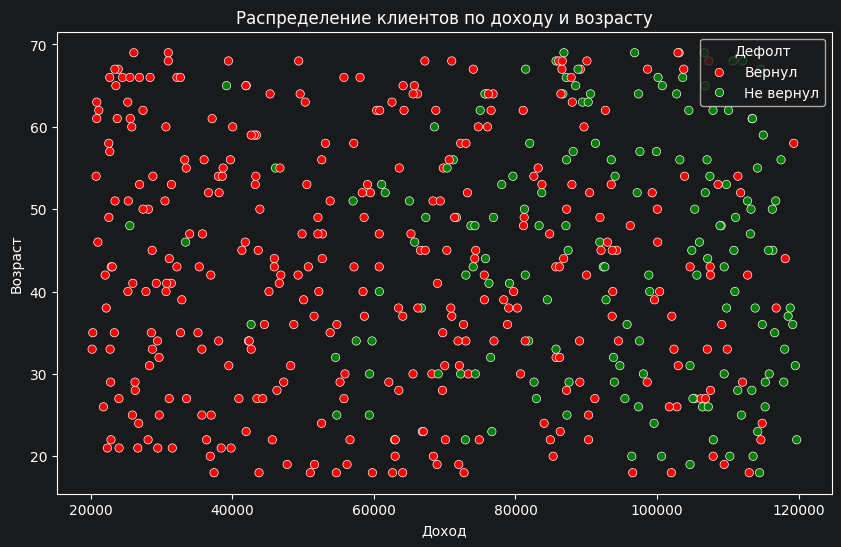

In [63]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=data, x='Income', y='Age', hue='Default', palette={0:'green',1:'red'})
plt.title('Распределение клиентов по доходу и возрасту')
plt.xlabel('Доход')
plt.ylabel('Возраст')
plt.legend(title='Дефолт', labels=['Вернул', 'Не вернул'])
plt.show()

Градиентный бустинг – один из самых мощных методов машинного обучения для
задач регрессии и классификации. Он основан на последовательном обучении слабых
моделей (обычно деревьев решений), которые исправляют ошибки своих
предшественников. Среди наиболее популярных реализаций градиентного бустинга
выделяются XGBoost, LightGBM и CatBoost – библиотеки, которые значительно ускорили и
упростили применение этого метода.

XGBoost (Extreme Gradient Boosting) был одной из первых реализаций градиентного
бустинга, ставшей популярной благодаря своей эффективности. Он использует технику
«слабого» бустинга, строя деревья решений на основе градиентного спуска, а также
включает регуляризацию, предотвращающую переобучение. Важной особенностью
XGBoost является его способность работать с разреженными данными – он умеет
автоматически обрабатывать пропущенные значения, что делает его удобным для
реальных задач.

In [64]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [65]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

In [66]:
params = {
"objective": "binary:logistic",
"max_depth": 6,
"learning_rate": 0.1,
"eval_metric": "logloss"
}

In [67]:
bst = xgb.train(params, dtrain, num_boost_round=100)

In [68]:
y_pred = (bst.predict(dtest) > 0.5).astype(int)

In [69]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.7533


LightGBM (Light Gradient Boosting Machine) разработан для быстрой работы на
больших наборах данных. В отличие от XGBoost, он строит деревья не построчно (levelwise),
а по листам (leaf-wise), что позволяет быстрее находить важные разбиения и
увеличивает эффективность модели.

In [70]:
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

In [71]:
train_data = lgb.Dataset(X_train, label=y_train)
test_data = lgb.Dataset(X_test, label=y_test, reference=train_data)

In [72]:
params = {
"objective": "regression",
"metric": "rmse",
"boosting_type": "gbdt",
"learning_rate": 0.05,
"num_leaves": 31
}

In [73]:
# Обучаем модель
model = lgb.train(params, train_data, num_boost_round=100, valid_sets=[test_data])

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000119 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 173
[LightGBM] [Info] Number of data points in the train set: 350, number of used features: 3
[LightGBM] [Info] Start training from score 0.671429
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -in

In [74]:
y_pred = model.predict(X_test)

In [76]:
rmse = mean_squared_error(y_test, y_pred)
print(f"RMSE: {rmse:.4f}")

RMSE: 0.1571


In [85]:
import catboost as cb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

In [87]:
# Создаем модель CatBoost
cat_features=np.random.binomial(1, default_prob.clip(0, 1))
model = cb.CatBoostClassifier(iterations=100, depth=6, learning_rate=0.1,cat_features=cat_features)
# Обучаем модель
model.fit(X_train, y_train, eval_set=(X_test, y_test))
# Делаем предсказания
y_pred = model.predict_proba(X_test)[:, 1]
# Оцениваем модель
auc = roc_auc_score(y_test, y_pred)
print(f"AUC: {auc:.4f}")

0:	learn: 0.6811234	test: 0.6810502	best: 0.6810502 (0)	total: 167ms	remaining: 16.5s
1:	learn: 0.6728148	test: 0.6712822	best: 0.6712822 (1)	total: 180ms	remaining: 8.81s
2:	learn: 0.6641392	test: 0.6625180	best: 0.6625180 (2)	total: 211ms	remaining: 6.82s
3:	learn: 0.6579354	test: 0.6555233	best: 0.6555233 (3)	total: 219ms	remaining: 5.26s
4:	learn: 0.6525279	test: 0.6492667	best: 0.6492667 (4)	total: 233ms	remaining: 4.42s
5:	learn: 0.6466611	test: 0.6446698	best: 0.6446698 (5)	total: 275ms	remaining: 4.3s
6:	learn: 0.6413295	test: 0.6402988	best: 0.6402988 (6)	total: 309ms	remaining: 4.1s
7:	learn: 0.6373755	test: 0.6359009	best: 0.6359009 (7)	total: 345ms	remaining: 3.97s
8:	learn: 0.6339108	test: 0.6328624	best: 0.6328624 (8)	total: 433ms	remaining: 4.37s
9:	learn: 0.6296353	test: 0.6313347	best: 0.6313347 (9)	total: 528ms	remaining: 4.75s
10:	learn: 0.6260809	test: 0.6294935	best: 0.6294935 (10)	total: 592ms	remaining: 4.79s
11:	learn: 0.6235059	test: 0.6273602	best: 0.6273602 (

Выбор между XGBoost, LightGBM и CatBoost

XGBoost – универсальное решение с балансом между скоростью и качеством. Подходит
для широкого спектра задач, особенно если данные хорошо подготовлены.
LightGBM – оптимальный выбор для больших объемов данных, когда важна скорость
обучения.
CatBoost – лучший вариант при наличии большого количества категориальных признаков,
особенно если их обработка сложна.
В реальных задачах стоит попробовать несколько алгоритмов и выбрать тот,
который показывает наилучшие результаты на ваших данных.